# 2. Обучение PINN: гармоническое гидропрослушивание и приёмы, которые заставляют PINN работать

В ноутбуке 1 PINN экстраполировала затухающий осциллятор там, где обычное обучение с учителем не справилось. Та задача была простой: одно ОДУ, гладкое решение, несколько секунд обучения. Здесь мы переходим к уравнению в частных производных и задаём практический вопрос: **что делать, когда ванильная PINN не обучается?**

Задача — **гармоническое гидропрослушивание**: давление в скважине периодически меняется, а волна давления затухает вглубь пласта. У задачи есть точное решение, оно **гладкое** (никаких скачков и сингулярностей), а сложность регулируется одним числом: сколько периодов колебаний мы моделируем. На одном периоде ванильная PINN справляется, на восьми — нет.

Мы улучшаем PINN **по одному приёму за раз** и после каждого шага измеряем ошибку относительно точного решения, а не лосс:

| Шаг | Приём | Что исправляет |
|---|---|---|
| 0 | Обезразмеривание | слагаемые лосса, различающиеся на десятки порядков |
| 1 | Базовая PINN, 1 и 8 периодов | (отправная точка) |
| 2 | Фурье-признаки | спектральное смещение: сеть плохо учит высокие частоты |
| 3 | Масштаб Фурье-признаков из физики | признаки, не попадающие в частоту решения |
| 4 | Жёсткие граничные условия | веса условий и их ошибки |
| 5 | Adam → L-BFGS | медленная финальная сходимость методов первого порядка |

Приёмы взяты из обзора S. Wang, S. Sankaran, H. Wang, P. Perdikaris, [*An Expert's Guide to Training Physics-informed Neural Networks*](https://arxiv.org/abs/2308.08468) (2023).

**Главный урок:** малый лосс не означает точного решения. Точность PINN проверяют только по независимому эталону.

## 1. Физическая задача

**Гармоническое гидропрослушивание** (harmonic pulse testing): в возмущающей скважине давление (или дебит) меняют периодически, а в соседней, наблюдательной скважине регистрируют отклик. Волна давления в пласте **затухает** и **запаздывает**: по отношению амплитуд и сдвигу фаз определяют пьезопроводность пласта между скважинами. В отличие от обычного гидропрослушивания, периодический сигнал легко выделить на фоне шумов и дрейфа давления, а испытание можно проводить без остановки добычи.

**Модель:** однородный пласт, однофазная слабосжимаемая жидкость, закон Дарси, линейное течение от скважины ($x=0$) до непроницаемой границы ($x=L$):
$$
\frac{\partial p}{\partial t}=\eta\,\frac{\partial^2 p}{\partial x^2},\qquad \eta=\frac{k}{\phi\,\mu\,c_t},
$$
$$
p(0,t)=\bar p+A\sin\omega t,\qquad \frac{\partial p}{\partial x}(L,t)=0,\qquad \omega=\frac{2\pi}{P}.
$$
Нас интересует **установившийся периодический режим**: колебания идут давно, переходный процесс закончился. Начальное условие — состояние пласта в этом режиме в момент $t=0$ (оно согласовано с граничными условиями, поэтому у решения нет ни скачков, ни сингулярностей).

**Скин-слой.** Волна затухает в $e$ раз на глубине
$$
\delta=\sqrt{\frac{2\eta}{\omega}}=\sqrt{\frac{\eta P}{\pi}}.
$$
**То же уравнение в геофизике** — это классическая задача Фурье о температурных волнах в грунте:

| | Гидропрослушивание | Сезонная температурная волна |
|---|---|---|
| величина | давление | температура |
| коэффициент | пьезопроводность $\eta\approx0.05$ м²/с | температуропроводность $\approx10^{-6}$ м²/с |
| период $P$ | 24 ч | 1 год |
| скин-слой $\delta$ | ≈ 37 м | ≈ 3 м |

Поэтому сезонные колебания температуры почти не проникают глубже 10–15 м (слой нулевых годовых амплитуд, многолетняя мерзлота), а приливные колебания уровня в скважинах (период 12.42 ч) используют, чтобы оценить свойства водоносных горизонтов.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from torch import nn

# float32: в 2 раза быстрее float64 на CPU, точности хватает
torch.set_default_dtype(torch.float32)
torch.set_num_threads(4)
np.random.seed(0)
torch.manual_seed(0)
print("PyTorch:", torch.__version__)

# Цветовая схема: тема seaborn «whitegrid», палитра husl и три собственных цвета
PINN_COLOR = "#5b5fb0"  # индиго: PINN
REFERENCE_COLOR = "#e3242b"  # красный, пунктир: точное решение
SAMPLES_COLOR = "#a1c9f4"  # пастельно-голубой
MLP_COLOR = "#36ada4"  # husl, бирюзовый
INK_COLOR = "#262626"
GRID_COLOR = "#cccccc"
REFERENCE_STYLE = {"color": REFERENCE_COLOR, "linestyle": "--", "linewidth": 2.0}
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans", "Liberation Sans", "sans-serif"],
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.edgecolor": GRID_COLOR,
        "axes.linewidth": 1.25,
        "axes.titlesize": 12,
        "axes.titlecolor": INK_COLOR,
        "axes.labelsize": 11,
        "axes.labelcolor": INK_COLOR,
        "grid.color": GRID_COLOR,
        "grid.linewidth": 1.0,
        "text.color": INK_COLOR,
        "xtick.color": INK_COLOR,
        "ytick.color": INK_COLOR,
        "xtick.bottom": False,
        "ytick.left": False,
        "legend.frameon": True,
        "legend.framealpha": 0.8,
        "legend.edgecolor": GRID_COLOR,
        "legend.fontsize": 9,
        "lines.solid_capstyle": "round",
    }
)
# Шаги лестницы приёмов по порядку
STAGE_COLORS = ["#f77189", "#bb9832", "#97a431", "#36ada4", "#a48cf4", PINN_COLOR]
PHASE_COLORS = plt.cm.Blues(np.linspace(0.4, 0.95, 4))

PyTorch: 2.15.0


## 2. Приём 0: обезразмеривание

Параметры пласта и испытания (типичный терригенный коллектор):

In [2]:
# Пласт и испытание (СИ)
mD = 9.869233e-16  # 1 миллидарси, м²
k = 10.0 * mD  # проницаемость
phi = 0.20  # пористость
mu = 1.0e-3  # вязкость нефти, Па·с
ct = 1.0e-9  # полная сжимаемость, 1/Па
L = 200.0  # расстояние от скважины до непроницаемой границы, м
x_obs_m = 50.0  # наблюдательная скважина, м
p_mean, A = 25e6, 0.5e6  # среднее давление и амплитуда колебаний, Па
P = 24 * 3600.0  # период, с
N_PERIODS = 8  # длительность испытания в периодах
day = 86400.0

eta = k / (phi * mu * ct)
delta_skin = np.sqrt(eta * P / np.pi)
kappa = eta * P / L**2  # безразмерная пьезопроводность (см. ниже)
x_obs = x_obs_m / L

print(f"пьезопроводность eta = {eta:.3e} м²/с")
print(f"скин-слой delta = {delta_skin:.1f} м  (delta / L = {delta_skin / L:.3f})")
print(f"безразмерная пьезопроводность kappa = eta P / L² = {kappa:.4f}")
print(f"длительность испытания {N_PERIODS} периодов = {N_PERIODS * P / day:.0f} сут")

пьезопроводность eta = 4.935e-02 м²/с
скин-слой delta = 36.8 м  (delta / L = 0.184)
безразмерная пьезопроводность kappa = eta P / L² = 0.1066
длительность испытания 8 периодов = 8 сут


Посмотрим, как выглядит лосс PINN, если подавать в сеть величины в СИ: $x$ в метрах, $t$ в секундах, $p$ в паскалях. Возьмём необученную сеть и вычислим три слагаемых: невязку уравнения, начальное условие (здесь грубо $p=\bar p$) и условие на скважине.

In [3]:
torch.manual_seed(0)
naive = nn.Sequential(
    nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1)
)
t_end = N_PERIODS * P
x = (L * torch.rand(2000, 1)).requires_grad_(True)
t = (t_end * torch.rand(2000, 1)).requires_grad_(True)
p = naive(torch.cat([x, t], dim=1))
p_t = torch.autograd.grad(p, t, torch.ones_like(p), create_graph=True)[0]
p_x = torch.autograd.grad(p, x, torch.ones_like(p), create_graph=True)[0]
p_xx = torch.autograd.grad(p_x, x, torch.ones_like(p_x))[0]
x_b, t_b = L * torch.rand(200, 1), t_end * torch.rand(200, 1)
with torch.no_grad():
    terms_si = {
        "невязка уравнения, (Па/с)²": ((p_t - eta * p_xx) ** 2).mean(),
        "начальное условие, Па²": (
            (naive(torch.cat([x_b, torch.zeros_like(x_b)], 1)) - p_mean) ** 2
        ).mean(),
        "условие на скважине, Па²": (
            (
                naive(torch.cat([torch.zeros_like(t_b), t_b], 1))
                - p_mean
                - A * torch.sin(2 * np.pi * t_b / P)
            )
            ** 2
        ).mean(),
    }
for name, value in terms_si.items():
    print(f"{name:28s} {value.item():.1e}")

невязка уравнения, (Па/с)²   8.4e-11
начальное условие, Па²       6.2e+14
условие на скважине, Па²     6.3e+14


Слагаемые различаются на **десятки порядков**: оптимизатор видит только условия, уравнение для него невидимо. Вдобавок вход $t\sim10^5$ насыщает $\tanh$ в первом слое, и выход сети почти не зависит от времени.

Безразмерные переменные: расстояние в долях $L$, время в периодах, давление в амплитудах:
$$
x_D=\frac{x}{L},\qquad t_D=\frac{t}{P},\qquad p_D=\frac{p-\bar p}{A}.
$$
Задача принимает вид
$$
\frac{\partial p_D}{\partial t_D}=\kappa\,\frac{\partial^2 p_D}{\partial x_D^2},\qquad
p_D(0,t_D)=\sin 2\pi t_D,\qquad \frac{\partial p_D}{\partial x_D}(1,t_D)=0,\qquad \kappa=\frac{\eta P}{L^2}=\pi\Big(\frac{\delta}{L}\Big)^2 .
$$
Все величины порядка единицы, а физика пласта вошла в **одно число** $\kappa$. Дальше индекс $D$ опускаем.

## 3. Точное решение

Ищем периодический режим в виде $p=\operatorname{Im}\big[G(x)\,e^{i\omega t}\big]$, $\omega=2\pi$. Подстановка в уравнение даёт $\kappa G''=i\omega G$, и с условиями $G(0)=1$, $G'(1)=0$:
$$
G(x)=\frac{\cosh\lambda(1-x)}{\cosh\lambda},\qquad \lambda=\sqrt{\frac{i\omega}{\kappa}}=(1+i)\frac{L}{\delta},\qquad
p(x,t)=|G(x)|\,\sin\big(2\pi t+\arg G(x)\big).
$$
$|G(x)|$ — **амплитуда** в точке $x$ относительно скважины, $-\arg G(x)$ — **запаздывание фазы**. Вдали от границы ($L\gg\delta$) $G\approx e^{-(1+i)x/\delta}$: амплитуда падает как $e^{-x/\delta}$, а фаза отстаёт на $x/\delta$ радиан. Именно по этим двум числам в наблюдательной скважине классически определяют $\eta$.

Начальное условие — то же решение при $t=0$: $p(x,0)=\operatorname{Im}G(x)$.

In [4]:
LAMBDA = np.sqrt(2j * np.pi / kappa)


def transfer(x):
    # Комплексная амплитуда G(x): |G| — амплитуда, -arg G — запаздывание фазы
    return np.cosh(LAMBDA * (1 - np.asarray(x, float))) / np.cosh(LAMBDA)


def exact_p(x, t):
    # Точное безразмерное давление p(x, t), установившийся режим
    x, t = np.broadcast_arrays(np.asarray(x, float), np.asarray(t, float))
    return np.imag(transfer(x) * np.exp(2j * np.pi * t))


# Проверки: уравнение и условия (конечные разности на точном решении)
h = 1e-4
xs, ts = np.linspace(0.05, 0.95, 7), np.linspace(0.1, 3.9, 7)
X, T = np.meshgrid(xs, ts)
p_t = (exact_p(X, T + h) - exact_p(X, T - h)) / (2 * h)
p_xx = (exact_p(X + h, T) - 2 * exact_p(X, T) + exact_p(X - h, T)) / h**2
print(
    "max |p_t - kappa p_xx|  =",
    f"{np.abs(p_t - kappa * p_xx).max():.1e}  (ошибка разностей)",
)
print(
    "max |p(0,t) - sin 2πt|  =", np.abs(exact_p(0.0, ts) - np.sin(2 * np.pi * ts)).max()
)
print(
    "max |p_x(1,t)|          =",
    f"{np.abs((exact_p(1.0, ts) - exact_p(1 - h, ts)) / h).max():.1e}",
)
G_obs = transfer(x_obs)
print(
    f"\nнаблюдательная скважина ({x_obs_m:.0f} м): амплитуда {abs(G_obs):.3f}, "
    f"запаздывание {-np.angle(G_obs):.3f} рад = {-np.angle(G_obs) * P / (2 * np.pi) / 3600:.1f} ч"
)
print(
    f"полубесконечный пласт:        амплитуда {np.exp(-x_obs_m / delta_skin):.3f}, "
    f"запаздывание {x_obs_m / delta_skin:.3f} рад"
)

max |p_t - kappa p_xx|  = 3.8e-07  (ошибка разностей)
max |p(0,t) - sin 2πt|  = 1.6906644956617803e-17
max |p_x(1,t)|          = 2.6e-05

наблюдательная скважина (50 м): амплитуда 0.257, запаздывание 1.358 рад = 5.2 ч
полубесконечный пласт:        амплитуда 0.257, запаздывание 1.357 рад


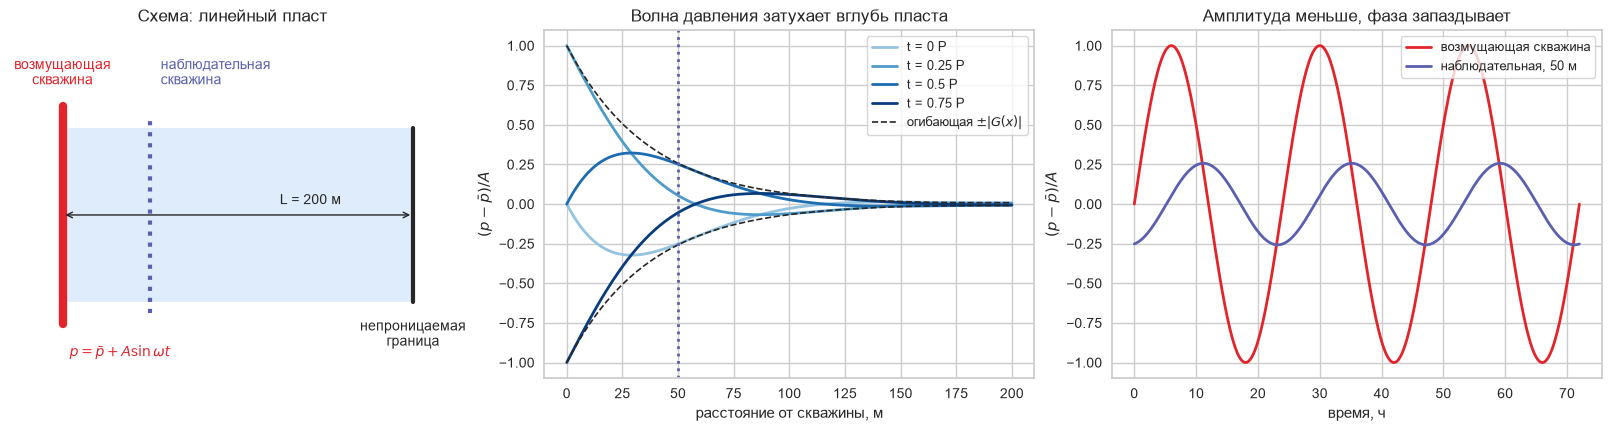

In [5]:
fig, ax = plt.subplots(
    1,
    3,
    figsize=(16, 4.2),
    gridspec_kw={"width_ratios": [1, 1.1, 1.1]},
    constrained_layout=True,
)

# Схема
a = ax[0]
a.set(xlim=(-0.15, 1.12), ylim=(-0.35, 1.25), title="Схема: линейный пласт")
a.axis("off")
a.add_patch(Rectangle((0, 0), 1, 0.8, color=SAMPLES_COLOR, alpha=0.35, lw=0))
a.plot([0, 0], [-0.1, 0.9], color=REFERENCE_COLOR, lw=6)
a.plot([1, 1], [0, 0.8], color=INK_COLOR, lw=3)
a.plot([x_obs, x_obs], [-0.05, 0.85], color=PINN_COLOR, lw=3, ls=":")
a.text(0, 1.0, "возмущающая\nскважина", color=REFERENCE_COLOR, ha="center", fontsize=10)
a.text(x_obs + 0.03, 1.0, "наблюдательная\nскважина", color=PINN_COLOR, fontsize=10)
a.text(1, -0.2, "непроницаемая\nграница", color=INK_COLOR, ha="center", fontsize=10)
a.text(0.02, -0.25, r"$p=\bar p + A\sin\omega t$", color=REFERENCE_COLOR, fontsize=10)
a.annotate(
    "",
    xy=(1, 0.4),
    xytext=(0, 0.4),
    arrowprops={"arrowstyle": "<->", "color": INK_COLOR},
)
a.text(0.62, 0.45, f"L = {L:.0f} м", fontsize=10)

# Профили в разные фазы и огибающая
x_plot = np.linspace(0, 1, 301)
for phase, c in zip([0, 0.25, 0.5, 0.75], PHASE_COLORS):
    ax[1].plot(
        x_plot * L, exact_p(x_plot, phase), color=c, lw=2, label=f"t = {phase:g} P"
    )
env = np.abs(transfer(x_plot))
ax[1].plot(
    x_plot * L, env, color=INK_COLOR, ls="--", lw=1.2, label=r"огибающая $\pm|G(x)|$"
)
ax[1].plot(x_plot * L, -env, color=INK_COLOR, ls="--", lw=1.2)
ax[1].axvline(x_obs_m, color=PINN_COLOR, ls=":", lw=2)
ax[1].set(
    xlabel="расстояние от скважины, м",
    ylabel=r"$(p-\bar p)/A$",
    title="Волна давления затухает вглубь пласта",
)
ax[1].legend(loc="upper right")

# Давление во времени: скважина и наблюдательная скважина
t_plot = np.linspace(0, 3, 600)
ax[2].plot(
    t_plot * P / 3600,
    exact_p(0.0, t_plot),
    color=REFERENCE_COLOR,
    lw=2,
    label="возмущающая скважина",
)
ax[2].plot(
    t_plot * P / 3600,
    exact_p(x_obs, t_plot),
    color=PINN_COLOR,
    lw=2,
    label=f"наблюдательная, {x_obs_m:.0f} м",
)
ax[2].set(
    xlabel="время, ч",
    ylabel=r"$(p-\bar p)/A$",
    title="Амплитуда меньше, фаза запаздывает",
)
ax[2].legend(loc="upper right")
plt.show()

Вся задача на $8$ периодах — карта давления $p(x,t)$. Каждая «полоса» — один период колебаний; волна заметна только в пределах нескольких $\delta$ от скважины.

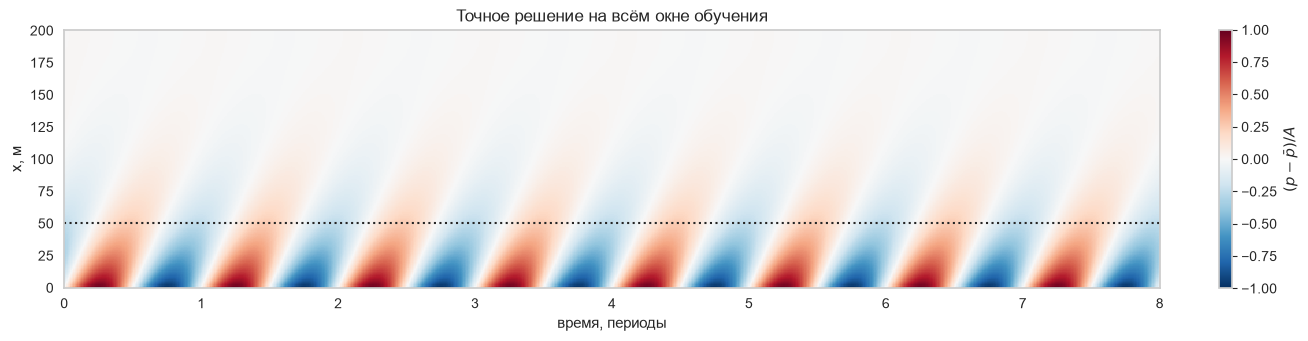

In [6]:
x_img = np.linspace(0, 1, 201)
t_img = np.linspace(0, N_PERIODS, 801)
fig, ax = plt.subplots(figsize=(13, 3.3), constrained_layout=True)
im = ax.pcolormesh(
    t_img,
    x_img * L,
    exact_p(x_img[:, None], t_img[None, :]),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    shading="auto",
)
ax.axhline(x_obs_m, color=INK_COLOR, ls=":", lw=1.5)
ax.set(
    xlabel="время, периоды", ylabel="x, м", title="Точное решение на всём окне обучения"
)
ax.grid(False)
fig.colorbar(im, ax=ax, label=r"$(p-\bar p)/A$")
plt.show()

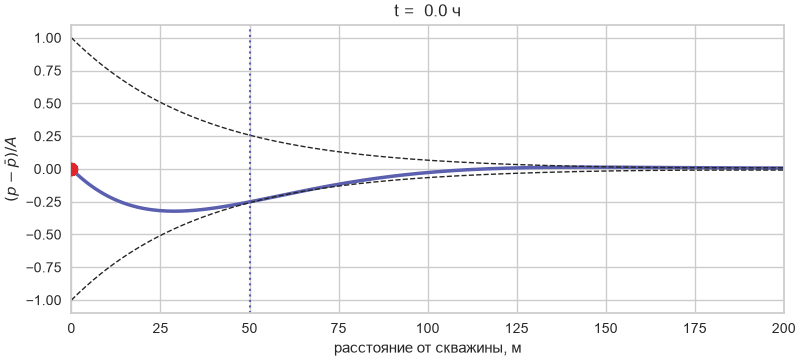

In [7]:
# Анимация: один период колебаний
frames = np.linspace(0, 1, 40, endpoint=False)
fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
(prof,) = ax.plot([], [], color=PINN_COLOR, lw=2.5)
(dot,) = ax.plot([], [], "o", color=REFERENCE_COLOR, ms=9, zorder=5)
ax.plot(x_plot * L, env, color=INK_COLOR, ls="--", lw=1)
ax.plot(x_plot * L, -env, color=INK_COLOR, ls="--", lw=1)
ax.axvline(x_obs_m, color=PINN_COLOR, ls=":", lw=1.5)
ax.set(
    xlim=(0, L),
    ylim=(-1.1, 1.1),
    xlabel="расстояние от скважины, м",
    ylabel=r"$(p-\bar p)/A$",
)
title = ax.set_title("")


def update(i):
    t = frames[i]
    prof.set_data(x_plot * L, exact_p(x_plot, t))
    dot.set_data([0], [exact_p(0.0, t)])
    title.set_text(f"t = {t * P / 3600:4.1f} ч")
    return prof, dot, title


anim = FuncAnimation(fig, update, frames=len(frames), blit=False)
gif_path = Path("../assets/harmonic_pressure_wave.gif")
gif_path.parent.mkdir(exist_ok=True)
anim.save(gif_path, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=gif_path))

> **Обсуждение.** Во сколько раз уменьшится амплитуда в наблюдательной скважине, если проницаемость в 4 раза меньше? Как изменится запаздывание? Почему для испытания на расстоянии 200 м период в сутки уже слишком мал?

## 4. Базовая PINN

Сеть $\hat p(x,t;\theta)$ должна **удовлетворять уравнению** в случайных точках области и **начальному и граничным условиям**:
$$
\mathcal L(\theta)=
\underbrace{\big\langle(\partial_t\hat p-\kappa\,\partial_{xx}\hat p)^2\big\rangle}_{\text{уравнение}}
+\underbrace{\big\langle(\hat p(x,0)-p_0(x))^2\big\rangle}_{\text{начальное}}
+\underbrace{\big\langle(\hat p(0,t)-\sin2\pi t)^2\big\rangle}_{\text{скважина}}
+\underbrace{\big\langle\partial_x\hat p(1,t)^2\big\rangle}_{\text{граница}}.
$$
Ни сетки, ни обучающих данных: только уравнение и условия. Производные — автоматическим дифференцированием (см. ноутбук 1).

### 4.1 Одна функция обучения для всех экспериментов

Все эксперименты используют **одну и ту же** сеть (4 скрытых слоя по 64 нейрона, $\tanh$), одинаковое число точек коллокации (1024 внутри, по 128 на начальной линии и границах, новые на каждом шаге) и одинаковый бюджет: 4000 шагов Adam со скоростью обучения, убывающей от $10^{-3}$ до $10^{-4}$. Входы масштабируются в $[-1,1]$. Каждый приём — аргумент `train_pinn`:

| Аргумент | Приём |
|---|---|
| `n_periods` | длина окна по времени: сложность задачи |
| `sigma_x`, `sigma_t` | Фурье-признаки и их масштабы (шаги 2–3) |
| `hard` | условия на скважине и на границе встроены в сеть (шаг 4) |
| `lbfgs` | завершить обучение L-BFGS (шаг 5) |
| `gradnorm`, `causal` | адаптивные веса и причинное обучение (раздел 7) |

In [8]:
class PINN(nn.Module):
    # (x, t) -> p. Входы масштабируются в [-1, 1]; t по окну [0, n_periods].
    # sigma_x, sigma_t > 0: случайные Фурье-признаки [cos Bz, sin Bz], B ~ N(0, diag(sigma_x², sigma_t²)).
    # hard=True: p = sin(2πt)(1 - ξ) + ξ N(ξ, t), ξ = 2x - x²: условия на скважине и границе выполняются точно.

    def __init__(
        self,
        n_periods,
        sigma_x=0.0,
        sigma_t=0.0,
        hard=False,
        n_ff=64,
        width=64,
        depth=4,
        seed=0,
    ):
        super().__init__()
        self.T, self.hard = n_periods, hard
        self.fourier = sigma_x > 0 or sigma_t > 0
        n_in = 2
        if self.fourier:
            g = torch.Generator().manual_seed(seed + 100)
            B = torch.randn(2, n_ff, generator=g) * torch.tensor([[sigma_x], [sigma_t]])
            self.register_buffer("B", B)
            n_in = 2 * n_ff
        layers = []
        for i in range(depth):
            layers += [nn.Linear(n_in if i == 0 else width, width), nn.Tanh()]
        layers += [nn.Linear(width, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x, t):
        xi = 2 * x - x * x
        z = torch.cat([2 * (xi if self.hard else x) - 1, 2 * t / self.T - 1], dim=1)
        if self.fourier:
            zb = z @ self.B
            z = torch.cat([torch.cos(zb), torch.sin(zb)], dim=1)
        n = self.net(z)
        if self.hard:
            return torch.sin(2 * np.pi * t) * (1 - xi) + xi * n
        return n


def grad(u, x):
    return torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]


def p0(x):
    # Начальное условие: точное решение при t = 0
    return torch.tensor(exact_p(x.numpy(), 0.0), dtype=x.dtype)


def loss_terms(model, x_f, t_f, x_0, t_b, causal=False, eps=1.0, M=16):
    x = x_f.clone().requires_grad_(True)
    t = t_f.clone().requires_grad_(True)
    p = model(x, t)
    r2 = (grad(p, t) - kappa * grad(grad(p, x), x)) ** 2
    weights = None
    if causal:  # точки идут по M отрезкам времени подряд; вес отрезка — exp(-eps * сумма невязок раньше)
        L_chunk = r2.reshape(M, -1).mean(1)
        with torch.no_grad():
            weights = torch.exp(
                -eps * torch.cumsum(torch.cat([torch.zeros(1), L_chunk[:-1]]), 0)
            )
        terms = {"уравнение": (weights * L_chunk).mean()}
    else:
        terms = {"уравнение": r2.mean()}
    terms["начальное"] = ((model(x_0, torch.zeros_like(x_0)) - p0(x_0)) ** 2).mean()
    if not model.hard:
        x_1 = torch.ones_like(t_b).requires_grad_(True)
        terms["скважина"] = (
            (model(torch.zeros_like(t_b), t_b) - torch.sin(2 * np.pi * t_b)) ** 2
        ).mean()
        terms["граница"] = (grad(model(x_1, t_b), x_1) ** 2).mean()
    return terms, weights


ADAM_STEPS, N_F, N_B, M_CAUSAL = 4000, 1024, 128, 16


def train_pinn(
    n_periods=N_PERIODS,
    sigma_x=0.0,
    sigma_t=0.0,
    hard=False,
    lbfgs=0,
    gradnorm=False,
    causal=False,
    eps=1.0,
    seed=0,
):
    torch.manual_seed(seed)
    T = n_periods
    model = PINN(T, sigma_x, sigma_t, hard, seed=seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, 0.1 ** (1 / ADAM_STEPS))
    lam, history, causal_w = {}, [], []
    start = time.time()
    for step in range(ADAM_STEPS):
        if causal:  # по N_F / M точек в каждом из M отрезков времени
            t_f = (
                (
                    torch.arange(M_CAUSAL).repeat_interleave(N_F // M_CAUSAL)[:, None]
                    + torch.rand(N_F, 1)
                )
                * T
                / M_CAUSAL
            )
        else:
            t_f = T * torch.rand(N_F, 1)
        x_f, x_0, t_b = torch.rand(N_F, 1), torch.rand(N_B, 1), T * torch.rand(N_B, 1)
        terms, w = loss_terms(model, x_f, t_f, x_0, t_b, causal, eps, M_CAUSAL)
        if not lam:
            lam = {name: 1.0 for name in terms}
        if gradnorm and step % 100 == 0:
            # веса по нормам градиентов: λ_i = Σ|∇L_j| / |∇L_i|, скользящее среднее
            params = list(model.parameters())
            norms = {}
            for name, v in terms.items():
                g = torch.autograd.grad(v, params, retain_graph=True, allow_unused=True)
                norms[name] = torch.sqrt(
                    sum((gi**2).sum() for gi in g if gi is not None)
                ).item()
            total = sum(norms.values())
            for name in terms:
                lam[name] = 0.9 * lam[name] + 0.1 * total / (norms[name] + 1e-12)
        loss = sum(lam[name] * v for name, v in terms.items())
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 10 == 0:
            history.append({name: v.item() for name, v in terms.items()})
            if causal and step % 100 == 0:
                causal_w.append(w.numpy().copy())

    if lbfgs:
        # L-BFGS нужен фиксированный набор точек для линейного поиска
        torch.manual_seed(seed + 1)
        fixed = (
            torch.rand(4096, 1),
            T * torch.rand(4096, 1),
            torch.rand(256, 1),
            T * torch.rand(256, 1),
        )
        opt2 = torch.optim.LBFGS(
            model.parameters(),
            lr=1.0,
            max_iter=lbfgs,
            history_size=50,
            line_search_fn="strong_wolfe",
            tolerance_grad=1e-12,
            tolerance_change=1e-15,
        )

        def closure():
            opt2.zero_grad()
            x_f, t_f, x_0, t_b = fixed
            terms, _ = loss_terms(model, x_f, t_f, x_0, t_b)
            loss = sum(lam[name] * v for name, v in terms.items())
            loss.backward()
            return loss

        opt2.step(closure)

    model.train_time = time.time() - start
    model.history, model.lam, model.causal_w = history, lam, np.array(causal_w)
    return model


print(
    "обучаемых параметров (без Фурье-признаков):",
    sum(p.numel() for p in PINN(N_PERIODS).parameters()),
)

обучаемых параметров (без Фурье-признаков): 12737


### 4.2 Независимые метрики

Лосс **не** является метрикой точности. Каждую модель оцениваем относительно точного решения на всём окне обучения:
- **относительная $L_2$-ошибка** давления по всей области $(x,t)$ — основная метрика;
- **ошибка по периодам**: где во времени модель ошибается;
- **амплитуда и фаза в наблюдательной скважине** — то, что реально измеряют при гидропрослушивании и по чему определяют $\eta$. Ошибку фазы приводим в минутах запаздывания.

Итоговый лосс тоже выводится, на новых точках коллокации, чтобы его можно было сравнить с настоящей ошибкой.

In [9]:
results, models = {}, {}
X_EVAL = np.linspace(0, 1, 101)


def predict(model, x, t):
    x, t = np.broadcast_arrays(np.asarray(x, float), np.asarray(t, float))
    with torch.no_grad():
        out = model(
            torch.tensor(x.reshape(-1, 1), dtype=torch.float32),
            torch.tensor(t.reshape(-1, 1), dtype=torch.float32),
        )
    return out.numpy().reshape(x.shape)


def eval_grid(model):
    t = np.linspace(0, model.T, 50 * model.T + 1)
    X, T = np.meshgrid(X_EVAL, t)
    return X, T, predict(model, X, T), exact_p(X, T)


def amplitude_phase(model, x):
    # МНК-подгонка p(x, t) ≈ a sin 2πt + b cos 2πt по всему окну: амплитуда и фаза
    t = np.linspace(0, model.T, 50 * model.T + 1)
    S = np.c_[np.sin(2 * np.pi * t), np.cos(2 * np.pi * t)]
    a, b = np.linalg.lstsq(S, predict(model, x, t), rcond=None)[0]
    return np.hypot(a, b), np.arctan2(b, a)


def evaluate(model):
    _, T, P_hat, P_ex = eval_grid(model)
    rel = np.linalg.norm(P_hat - P_ex) / np.linalg.norm(P_ex)
    per_period = [
        np.linalg.norm((P_hat - P_ex)[(T[:, 0] >= k) & (T[:, 0] <= k + 1)])
        / np.linalg.norm(P_ex[(T[:, 0] >= k) & (T[:, 0] <= k + 1)])
        for k in range(model.T)
    ]
    amp, ph = amplitude_phase(model, x_obs)
    torch.manual_seed(123)
    terms, _ = loss_terms(
        model,
        torch.rand(4096, 1),
        model.T * torch.rand(4096, 1),
        torch.rand(256, 1),
        model.T * torch.rand(256, 1),
    )
    metrics = {
        "периодов": model.T,
        "итоговый лосс": sum(v.item() for v in terms.values()),
        "отн. L2-ошибка p": rel,
        "ошибка амплитуды, %": 100 * abs(amp / abs(G_obs) - 1),
        "ошибка фазы, мин": abs(np.angle(np.exp(1j * (ph - np.angle(G_obs)))))
        * P
        / (2 * np.pi)
        / 60,
        "время, с": model.train_time,
    }
    return metrics, per_period


def print_table():
    names = list(results)
    print(f"{'':22}" + "".join(f"{n:>20}" for n in names))
    for key in next(iter(results.values()))[0]:
        print(f"{key:22}" + "".join(f"{results[n][0][key]:20.3g}" for n in names))


def run_stage(name, **config):
    model = train_pinn(**config)
    models[name] = model
    results[name] = evaluate(model)
    print_table()


def plot_stage(name):
    # Карта ошибки, давление в наблюдательной скважине и ошибка по периодам для одной модели
    model = models[name]
    X, T, P_hat, P_ex = eval_grid(model)
    fig, ax = plt.subplots(
        1,
        3,
        figsize=(16, 3.8),
        gridspec_kw={"width_ratios": [1.5, 1.2, 0.8]},
        constrained_layout=True,
    )
    im = ax[0].pcolormesh(
        T,
        X * L,
        np.abs(P_hat - P_ex),
        norm=LogNorm(1e-4, 1),
        cmap="Blues",
        shading="auto",
    )
    fig.colorbar(im, ax=ax[0], label="|ошибка p|")
    ax[0].set(xlabel="время, периоды", ylabel="x, м", title="Карта ошибки (лог. шкала)")
    ax[0].grid(False)

    t = np.linspace(0, model.T, 400 * model.T)
    for xx, c in [(0.0, REFERENCE_COLOR), (x_obs, PINN_COLOR)]:
        ax[1].plot(t, exact_p(xx, t), color=INK_COLOR, lw=2.5, alpha=0.35)
        ax[1].plot(
            t,
            predict(model, xx, t),
            "--",
            color=c,
            lw=1.5,
            label=f"PINN, x = {xx * L:.0f} м",
        )
    ax[1].plot([], [], color=INK_COLOR, lw=2.5, alpha=0.35, label="точное")
    ax[1].set(
        xlabel="время, периоды",
        ylabel=r"$(p-\bar p)/A$",
        title="Скважина и наблюдательная скважина",
    )
    ax[1].legend(loc="lower left", fontsize=8)

    ax[2].bar(np.arange(1, model.T + 1), results[name][1], color=PINN_COLOR)
    ax[2].set(
        yscale="log",
        ylim=(1e-4, 3),
        xlabel="период",
        ylabel="отн. L2-ошибка",
        title="Ошибка по периодам",
    )
    fig.suptitle(name, fontsize=13)
    plt.show()

### 4.3 Шаг 1: базовая модель на одном периоде

Сначала короткое окно: один период колебаний. Обучение занимает ~30 с.

                        1a базовая, 1 пер.
периодов                                 1
итоговый лосс                     0.000916
отн. L2-ошибка p                     0.024
ошибка амплитуды, %                  0.876
ошибка фазы, мин                      2.27
время, с                                25


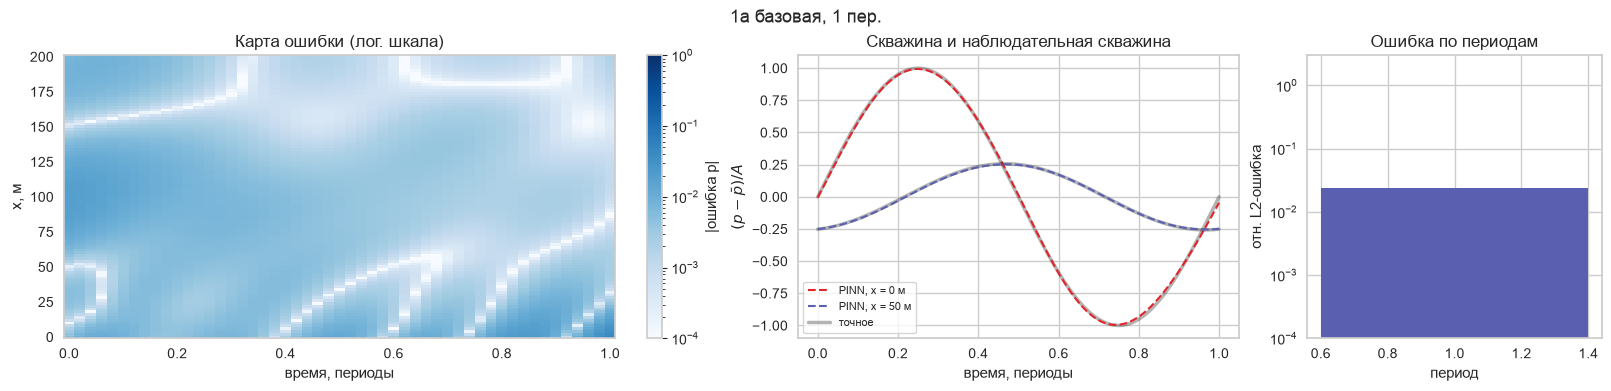

In [10]:
run_stage("1a базовая, 1 пер.", n_periods=1)
plot_stage("1a базовая, 1 пер.")

**Что мы видим.** На одном периоде ванильная PINN работает: ошибка порядка процента, амплитуда и фаза в наблюдательной скважине почти верны. Пока ничего особенного не нужно.

### Шаг 1: та же модель на восьми периодах

Испытание длится 8 суток, то есть 8 периодов. Задача та же, сеть та же, бюджет тот же. Пока идёт обучение: что, по-вашему, изменится?

                        1a базовая, 1 пер.          1b базовая
периодов                                 1                   8
итоговый лосс                     0.000916               0.479
отн. L2-ошибка p                     0.024                1.02
ошибка амплитуды, %                  0.876                99.1
ошибка фазы, мин                      2.27                 260
время, с                                25                  28


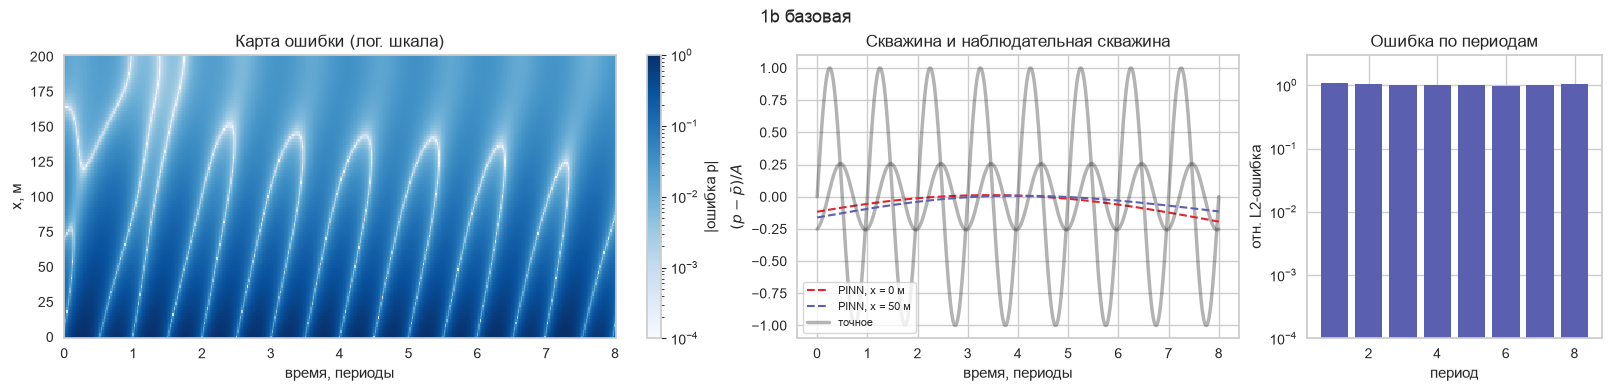

In [11]:
run_stage("1b базовая", n_periods=N_PERIODS)
plot_stage("1b базовая")

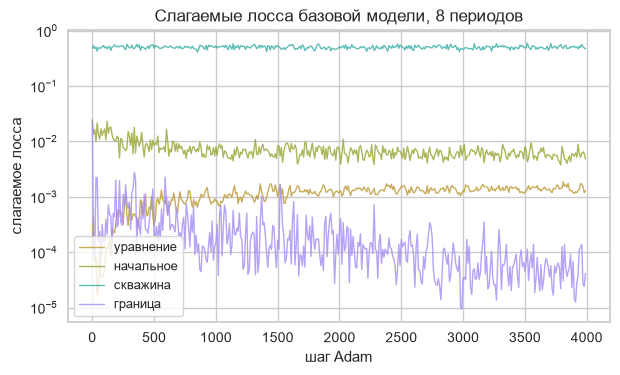

In [12]:
h = models["1b базовая"].history
fig, ax = plt.subplots(figsize=(7, 3.8))
for name, c in zip(h[0], STAGE_COLORS[1:]):
    ax.semilogy(
        np.arange(len(h)) * 10,
        [row[name] for row in h],
        color=c,
        lw=1,
        alpha=0.8,
        label=name,
    )
ax.set(
    xlabel="шаг Adam",
    ylabel="слагаемое лосса",
    title="Слагаемые лосса базовой модели, 8 периодов",
)
ax.legend()
plt.show()

**Что мы видим.** Ошибка около 100%: сеть выдаёт почти ноль, то есть пласт, в котором ничего не происходит. Невязка уравнения при этом маленькая — ноль тоже решение уравнения! Не выполнено лишь условие на скважине, и его слагаемое застряло около $\langle\sin^2\rangle=0.5$.

Почему на одном периоде получилось, а на восьми нет? Входное время масштабировано в $[-1,1]$, и восемь колебаний превращаются в функцию с угловой частотой $\pi T=8\pi\approx25$ по масштабированному времени $\tau$ (один период — частота $\pi$). Полносвязные сети с $\tanh$ обладают **спектральным смещением** (spectral bias): при градиентном обучении они сначала выучивают низкие частоты, а высокие — очень медленно. Сеть «видит» быстрые колебания граничного условия как шум и усредняет их в ноль.

## 5. Приёмы, по одному

### Шаг 2: Фурье-признаки

Вместо $(x,t)$ подадим на вход сети набор синусоид от них:
$$
\gamma(z)=\big[\cos(Bz),\ \sin(Bz)\big],\qquad z=(x,\tau)\in[-1,1]^2,\qquad B_{ij}\sim\mathcal N(0,\sigma^2),
$$
где $B$ — фиксированная случайная матрица $2\times64$ ([Tancik et al., *NeurIPS* 2020](https://arxiv.org/abs/2006.10739)). Теперь высокие частоты уже есть во входном слое, и сети достаточно научиться их комбинировать. [Обзор Wang et al.](https://arxiv.org/abs/2308.08468) рекомендует $\sigma\in[1,10]$; начнём со стандартного $\sigma=1$.

                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1
периодов                                 1                   8                   8
итоговый лосс                     0.000916               0.479               0.237
отн. L2-ошибка p                     0.024                1.02               0.707
ошибка амплитуды, %                  0.876                99.1                51.3
ошибка фазы, мин                      2.27                 260                3.74
время, с                                25                  28                52.5


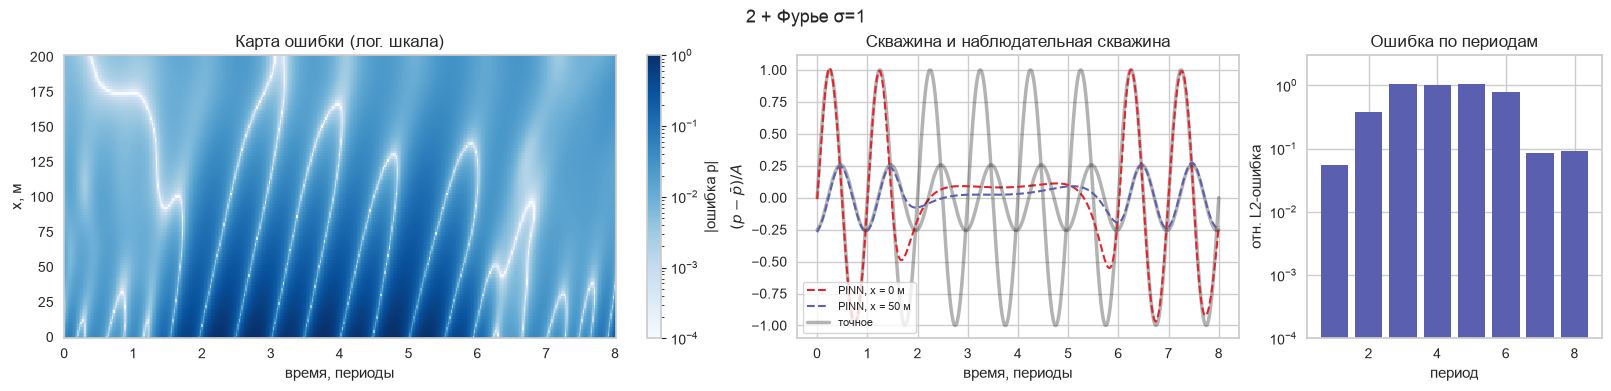

In [13]:
run_stage("2 + Фурье σ=1", sigma_x=1.0, sigma_t=1.0)
plot_stage("2 + Фурье σ=1")

**Что мы видим.** Стало лучше, но не хорошо: первый и последние периоды почти верны, а в середине окна сеть по-прежнему выдаёт ноль. Посмотрим, какие частоты по времени на самом деле содержат признаки:

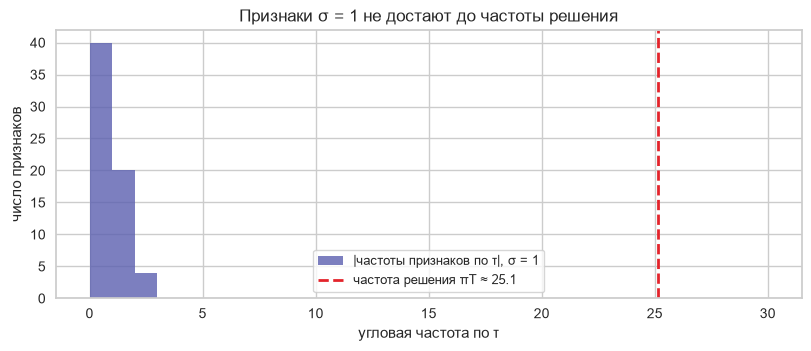

признаков с |частотой| > 12.6: 0 из 64


In [14]:
omega_tau = (
    np.pi * N_PERIODS
)  # частота решения по масштабированному времени τ = 2t/T - 1
fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
B_t = models["2 + Фурье σ=1"].B[1].numpy()
ax.hist(
    np.abs(B_t),
    bins=np.linspace(0, 30, 31),
    color=PINN_COLOR,
    alpha=0.8,
    label="|частоты признаков по τ|, σ = 1",
)
ax.axvline(omega_tau, label=f"частота решения πT ≈ {omega_tau:.1f}", **REFERENCE_STYLE)
ax.set(
    xlabel="угловая частота по τ",
    ylabel="число признаков",
    title="Признаки σ = 1 не достают до частоты решения",
)
ax.legend()
plt.show()
print(
    f"признаков с |частотой| > {omega_tau / 2:.1f}: {(np.abs(B_t) > omega_tau / 2).sum()} из {len(B_t)}"
)

### Шаг 3: масштаб Фурье-признаков из физики

Частота решения нам известна заранее: это частота воздействия. На масштабированном времени $\tau=2t/T-1$ она равна $2\pi\cdot T/2=\pi T$ — для 8 периодов около $25$, а признаки с $\sigma=1$ почти все меньше $3$. По пространству решение гладкое (скин-слой $\delta/L\approx0.18$), там $\sigma_x=1$ достаточно.

Берём **анизотропные** признаки: $\sigma_x=1$, $\sigma_t=\pi T/2$. Частоты признаков по времени распределены примерно до $2\sigma_t=\pi T$, то есть покрывают диапазон от нуля до частоты решения.

Это общий урок: гиперпараметры архитектуры стоит выводить **из масштабов задачи**, а не брать по умолчанию из статьи.

                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1   3 + σ_t из физики
периодов                                 1                   8                   8                   8
итоговый лосс                     0.000916               0.479               0.237            0.000462
отн. L2-ошибка p                     0.024                1.02               0.707              0.0123
ошибка амплитуды, %                  0.876                99.1                51.3               0.179
ошибка фазы, мин                      2.27                 260                3.74               0.155
время, с                                25                  28                52.5                49.5


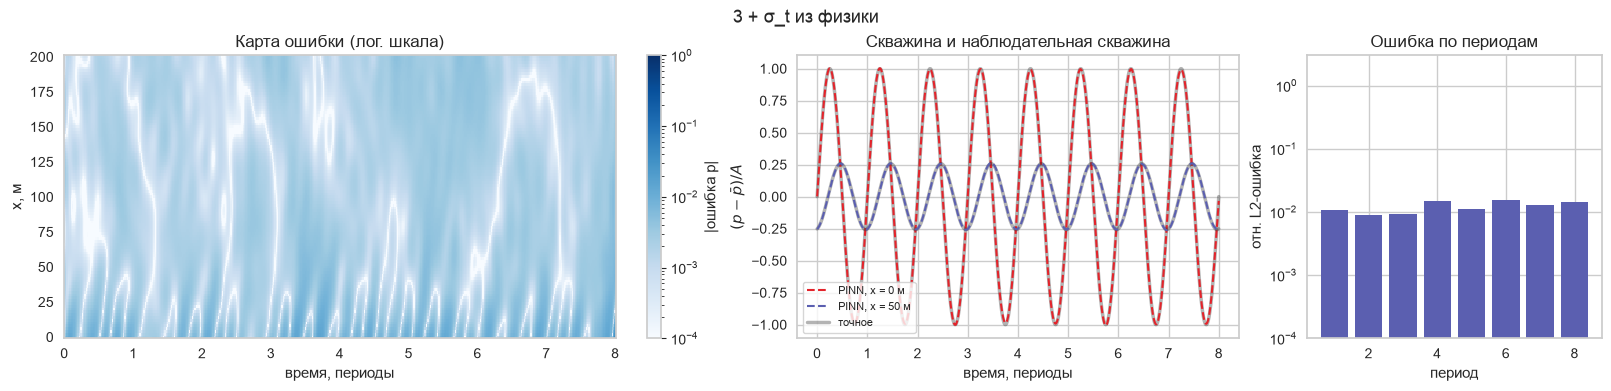

In [15]:
SIGMA_T = np.pi * N_PERIODS / 2
run_stage("3 + σ_t из физики", sigma_x=1.0, sigma_t=SIGMA_T)
plot_stage("3 + σ_t из физики")

### Шаг 4: жёсткие граничные условия

Условие на скважине — единственное, что «раскачивает» пласт. Пока оно слагаемое лосса, оно выполняется приближённо и соревнуется с уравнением. Встроим условия в сеть:
$$
\hat p(x,t)=\sin(2\pi t)\,(1-\xi)+\xi\,N(\xi,t),\qquad \xi=2x-x^2 .
$$
- $x=0$: $\xi=0$, поэтому $\hat p=\sin2\pi t$ — условие на скважине выполняется точно;
- $x=1$: $\partial_x\xi=2-2x=0$, а сеть зависит от $x$ только через $\xi$, поэтому $\partial_x\hat p(1,t)=0$ точно.

В лоссе остаются уравнение и начальное условие. Проверим условия через autograd на необученной сети:

In [16]:
torch.manual_seed(0)
check = PINN(N_PERIODS, 1.0, SIGMA_T, hard=True)
t_b = N_PERIODS * torch.rand(5, 1)
x_1 = torch.ones_like(t_b).requires_grad_(True)
print(
    "max |p(0,t) - sin 2πt| =",
    (check(torch.zeros_like(t_b), t_b) - torch.sin(2 * np.pi * t_b)).abs().max().item(),
)
print("max |p_x(1,t)|         =", grad(check(x_1, t_b), x_1).abs().max().item())

max |p(0,t) - sin 2πt| = 0.0
max |p_x(1,t)|         = 0.0


                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1   3 + σ_t из физики      4 + жёсткие ГУ
периодов                                 1                   8                   8                   8                   8
итоговый лосс                     0.000916               0.479               0.237            0.000462            0.000343
отн. L2-ошибка p                     0.024                1.02               0.707              0.0123              0.0112
ошибка амплитуды, %                  0.876                99.1                51.3               0.179               0.088
ошибка фазы, мин                      2.27                 260                3.74               0.155               0.134
время, с                                25                  28                52.5                49.5                55.5


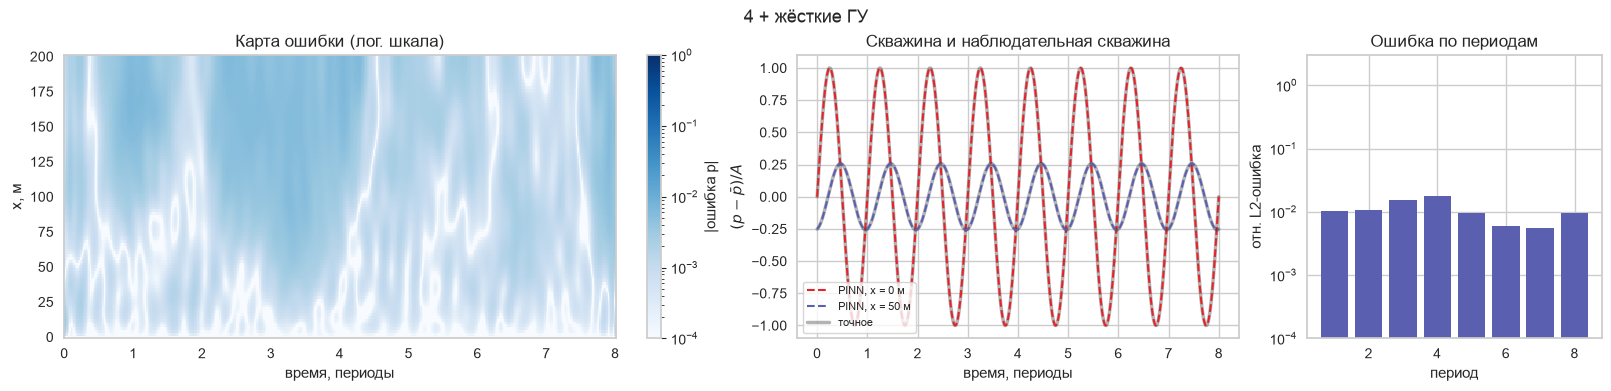

In [17]:
run_stage("4 + жёсткие ГУ", sigma_x=1.0, sigma_t=SIGMA_T, hard=True)
plot_stage("4 + жёсткие ГУ")

### Шаг 5: Adam, затем L-BFGS

Adam надёжен в начале, но к концу сходится медленно: его шумные шаги по случайным точкам годятся для разведки, а не для точности. Лосс PINN на фиксированном наборе точек — гладкая детерминированная функция, именно для таких задач созданы квазиньютоновские методы. **L-BFGS** строит приближение кривизны по последним градиентам и делает длинные, хорошо масштабированные шаги.

Стандартный рецепт: Adam, чтобы попасть в нужную область, затем 500 итераций L-BFGS на фиксированном наборе точек, чтобы дожать.

                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1   3 + σ_t из физики      4 + жёсткие ГУ          5 + L-BFGS
периодов                                 1                   8                   8                   8                   8                   8
итоговый лосс                     0.000916               0.479               0.237            0.000462            0.000343             0.00018
отн. L2-ошибка p                     0.024                1.02               0.707              0.0123              0.0112             0.00147
ошибка амплитуды, %                  0.876                99.1                51.3               0.179               0.088              0.0231
ошибка фазы, мин                      2.27                 260                3.74               0.155               0.134              0.0509
время, с                                25                  28                52.5                49.5                55.5                65.4

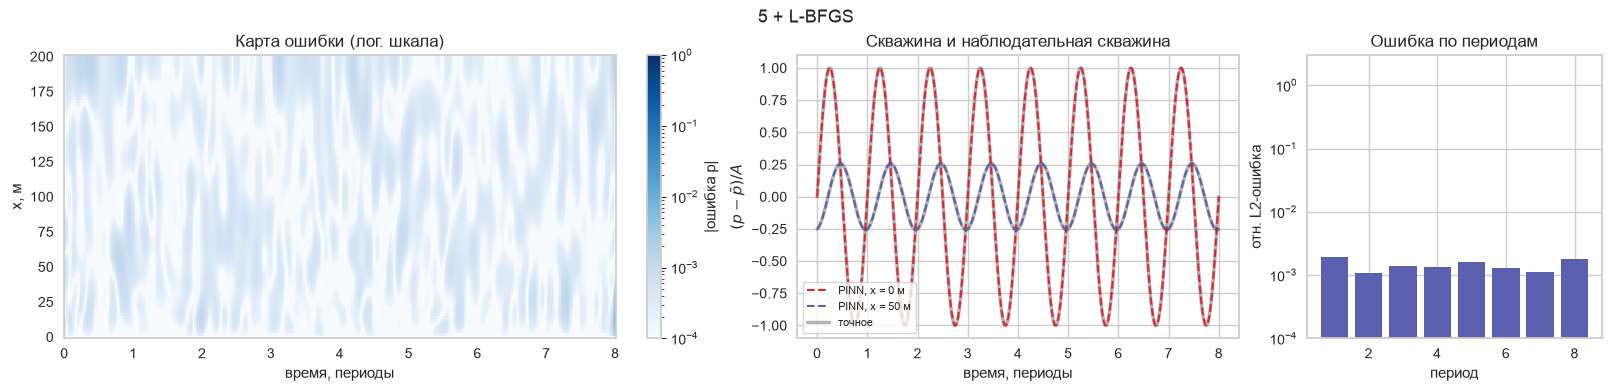

In [18]:
run_stage("5 + L-BFGS", sigma_x=1.0, sigma_t=SIGMA_T, hard=True, lbfgs=500)
plot_stage("5 + L-BFGS")

## 6. Итоги лестницы приёмов

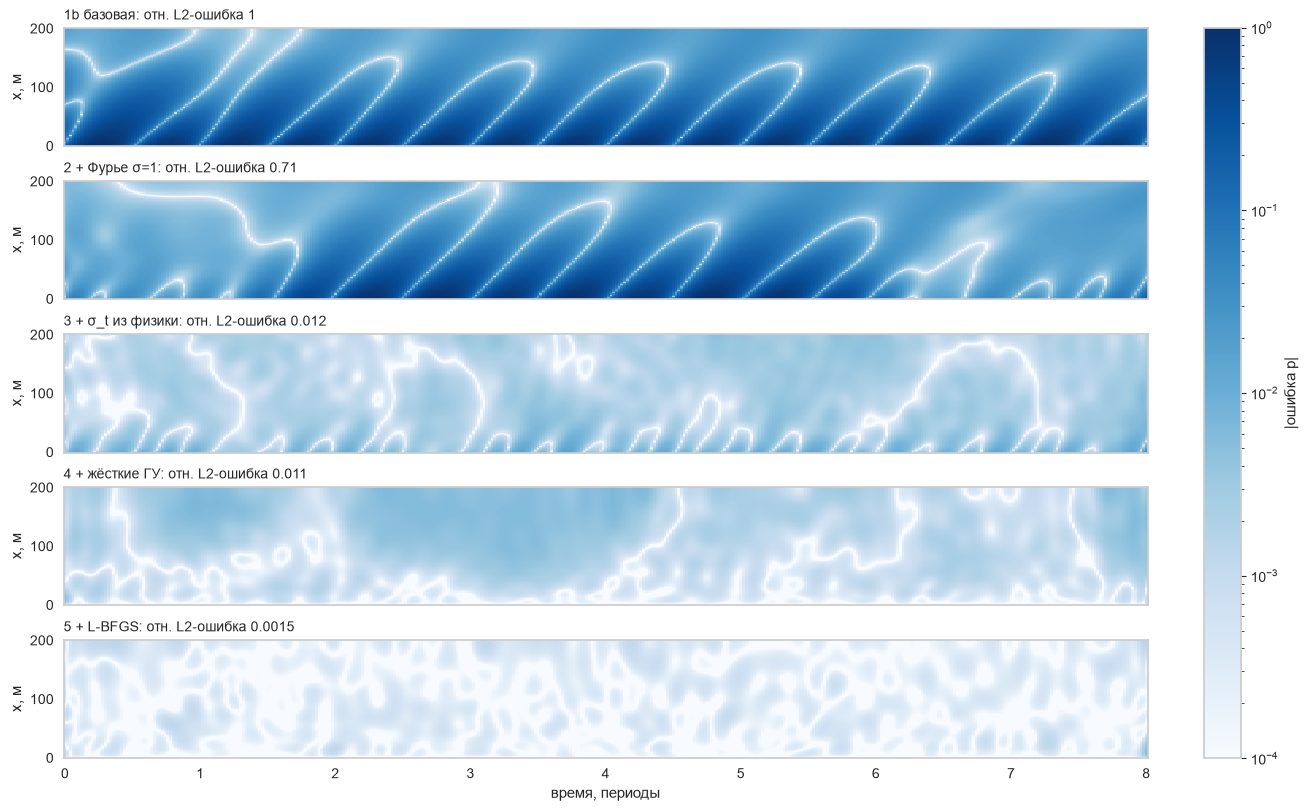

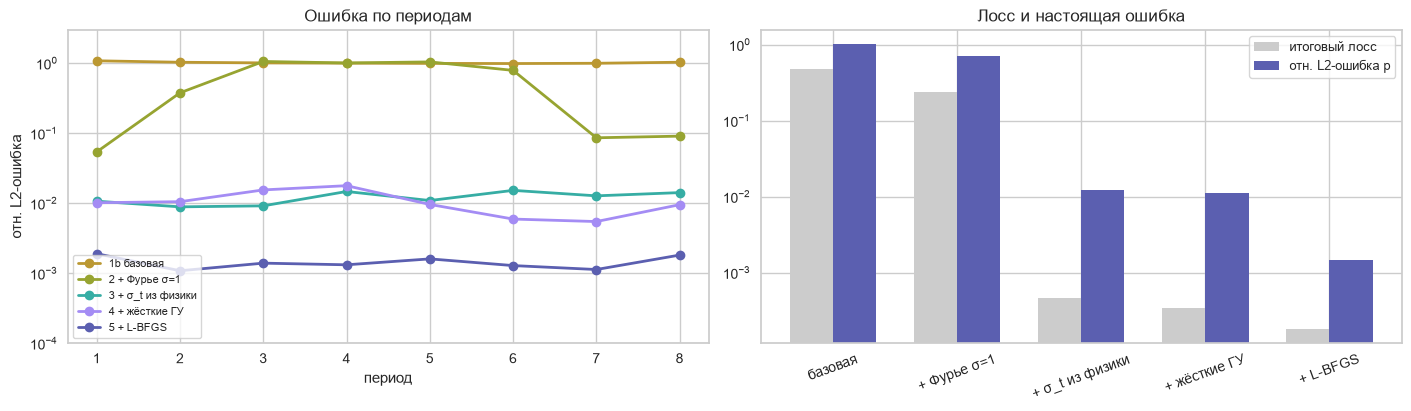

                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1   3 + σ_t из физики      4 + жёсткие ГУ          5 + L-BFGS
периодов                                 1                   8                   8                   8                   8                   8
итоговый лосс                     0.000916               0.479               0.237            0.000462            0.000343             0.00018
отн. L2-ошибка p                     0.024                1.02               0.707              0.0123              0.0112             0.00147
ошибка амплитуды, %                  0.876                99.1                51.3               0.179               0.088              0.0231
ошибка фазы, мин                      2.27                 260                3.74               0.155               0.134              0.0509
время, с                                25                  28                52.5                49.5                55.5                65.4

In [19]:
names = [n for n in results if results[n][0]["периодов"] == N_PERIODS]
fig, ax = plt.subplots(
    len(names), 1, figsize=(13, 1.6 * len(names)), sharex=True, constrained_layout=True
)
for a, name in zip(ax, names):
    X, T, P_hat, P_ex = eval_grid(models[name])
    im = a.pcolormesh(
        T,
        X * L,
        np.abs(P_hat - P_ex),
        norm=LogNorm(1e-4, 1),
        cmap="Blues",
        shading="auto",
    )
    a.set_ylabel("x, м")
    a.set_title(
        f"{name}: отн. L2-ошибка {results[name][0]['отн. L2-ошибка p']:.2g}",
        fontsize=10,
        loc="left",
    )
    a.grid(False)
ax[-1].set_xlabel("время, периоды")
fig.colorbar(im, ax=ax, label="|ошибка p|")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for name, c in zip(names, STAGE_COLORS[1:]):
    ax[0].semilogy(
        np.arange(1, N_PERIODS + 1), results[name][1], "o-", color=c, lw=2, label=name
    )
ax[0].set(
    xlabel="период", ylabel="отн. L2-ошибка", title="Ошибка по периодам", ylim=(1e-4, 3)
)
ax[0].legend(fontsize=8)

x_pos = np.arange(len(names))
for j, (key, c) in enumerate(
    [("итоговый лосс", GRID_COLOR), ("отн. L2-ошибка p", PINN_COLOR)]
):
    ax[1].bar(
        x_pos + (j - 0.5) * 0.35,
        [results[n][0][key] for n in names],
        width=0.35,
        color=c,
        label=key,
    )
ax[1].set(yscale="log", xticks=x_pos, title="Лосс и настоящая ошибка")
ax[1].set_xticklabels([n.split(" ", 1)[1] for n in names], rotation=20)
ax[1].legend()
plt.show()
print_table()

**Что показывает лестница** (сид 0; финальный рецепт на сидах 1 и 2 — в следующей ячейке):
- ошибка давления падает от ~100% у базовой модели до **0.15%** на шаге 5, почти на три порядка. Решающий шаг — 3: масштаб признаков по времени из физики (71% → 1.2%). Стандартные признаки с $\sigma=1$ помогли лишь частично: сеть выучила первые и последние периоды, а в середине окна выдаёт почти ноль;
- жёсткие условия (шаг 4) почти не меняют ошибку давления (1.2% → 1.1%), но вдвое уменьшают ошибку амплитуды и убирают из лосса два слагаемых с весами. L-BFGS (шаг 5) даёт ещё порядок: 1.1% → 0.15%;
- **инженерные величины**: амплитуда в наблюдательной скважине верна с точностью 0.02%, запаздывание фазы — с точностью около 3 с. На шаге 2 ошибка амплитуды 51%: определять проницаемость по такой модели бессмысленно, хотя на графике давления в скважине первые периоды выглядят идеально;
- здесь лосс и ошибка падают согласованно, но это не правило. У базовой модели невязка уравнения ~$10^{-3}$ при ошибке 100%: нулевое решение удовлетворяет уравнению. Правильно ранжируют модели только независимые ошибки.

In [20]:
# Повторяемость финального рецепта: другие сиды (~2.5 мин)
for seed in (1, 2):
    m = train_pinn(sigma_x=1.0, sigma_t=SIGMA_T, hard=True, lbfgs=500, seed=seed)
    r = evaluate(m)[0]
    print(
        f"seed {seed}: отн. L2-ошибка {r['отн. L2-ошибка p']:.2e}, амплитуда {r['ошибка амплитуды, %']:.2f}%, фаза {r['ошибка фазы, мин']:.1f} мин"
    )

seed 1: отн. L2-ошибка 2.00e-03, амплитуда 0.02%, фаза 0.1 мин


seed 2: отн. L2-ошибка 1.67e-03, амплитуда 0.04%, фаза 0.0 мин


## 7. Приёмы из статьи, которые здесь не помогают

В [обзоре Wang et al.](https://arxiv.org/abs/2308.08468) ещё два центральных приёма:
- **адаптивные веса по нормам градиентов** (grad norm, [Wang, Teng, Perdikaris, 2021](https://arxiv.org/abs/2001.04536)): вес слагаемого $\lambda_i=\sum_j\|\nabla_\theta\mathcal L_j\|/\|\nabla_\theta\mathcal L_i\|$, обновляется скользящим средним раз в 100 шагов. Лечит ситуацию, когда одно слагаемое забивает остальные;
- **причинное обучение** (causal training, [Wang, Sankaran, Perdikaris, 2024](https://arxiv.org/abs/2203.07404)): окно по времени делят на $M$ отрезков, и невязку на отрезке $i$ берут с весом $w_i=\exp\big(-\varepsilon\sum_{k<i}\mathcal L_r^{(k)}\big)$. Пока ранние времена не выучены, поздние почти не учатся. Лечит нарушение причинности: сеть выучивает поздние времена раньше ранних и сходится к неверному решению.

Проверим оба на конфигурации шага 2 (Фурье-признаки с σ = 1), которая проваливается: могут ли они её спасти?

In [21]:
run_stage("7a шаг 2 + веса", sigma_x=1.0, sigma_t=1.0, gradnorm=True)
run_stage("7b шаг 2 + причин.", sigma_x=1.0, sigma_t=1.0, causal=True, eps=1.0)

                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1   3 + σ_t из физики      4 + жёсткие ГУ          5 + L-BFGS     7a шаг 2 + веса
периодов                                 1                   8                   8                   8                   8                   8                   8
итоговый лосс                     0.000916               0.479               0.237            0.000462            0.000343             0.00018               0.299
отн. L2-ошибка p                     0.024                1.02               0.707              0.0123              0.0112             0.00147               0.822
ошибка амплитуды, %                  0.876                99.1                51.3               0.179               0.088              0.0231                68.9
ошибка фазы, мин                      2.27                 260                3.74               0.155               0.134              0.0509                2.82
время, с              

                        1a базовая, 1 пер.          1b базовая       2 + Фурье σ=1   3 + σ_t из физики      4 + жёсткие ГУ          5 + L-BFGS     7a шаг 2 + веса  7b шаг 2 + причин.
периодов                                 1                   8                   8                   8                   8                   8                   8                   8
итоговый лосс                     0.000916               0.479               0.237            0.000462            0.000343             0.00018               0.299                0.24
отн. L2-ошибка p                     0.024                1.02               0.707              0.0123              0.0112             0.00147               0.822               0.722
ошибка амплитуды, %                  0.876                99.1                51.3               0.179               0.088              0.0231                68.9                52.3
ошибка фазы, мин                      2.27                 260                3.74   

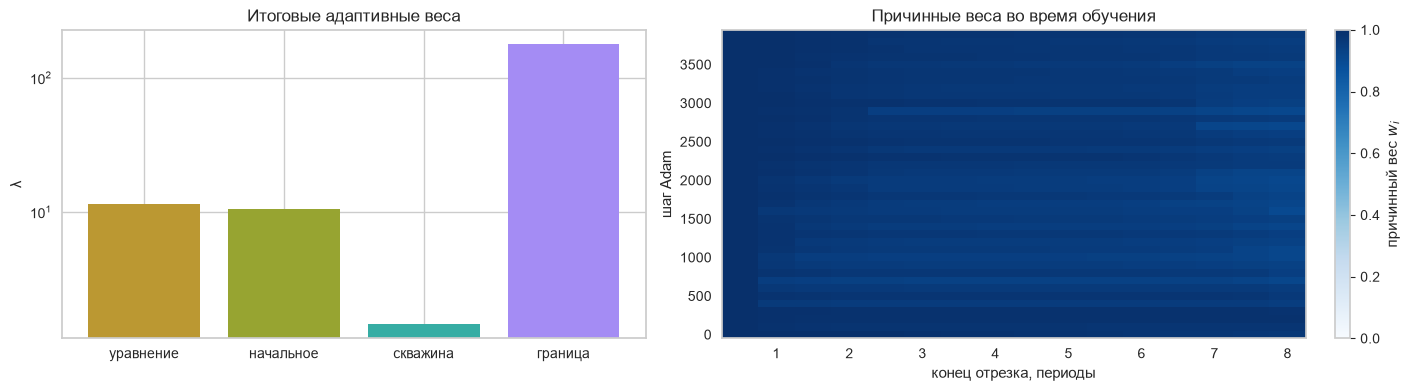

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
lam_hist = models["7a шаг 2 + веса"].lam
ax[0].bar(list(lam_hist), list(lam_hist.values()), color=STAGE_COLORS[1:5])
ax[0].set(yscale="log", title="Итоговые адаптивные веса", ylabel="λ")
cw = models["7b шаг 2 + причин."].causal_w
im = ax[1].pcolormesh(
    np.arange(1, M_CAUSAL + 1) * N_PERIODS / M_CAUSAL,
    np.arange(len(cw)) * 100,
    cw,
    cmap="Blues",
    vmin=0,
    vmax=1,
    shading="auto",
)
fig.colorbar(im, ax=ax[1], label="причинный вес $w_i$")
ax[1].set(
    xlabel="конец отрезка, периоды",
    ylabel="шаг Adam",
    title="Причинные веса во время обучения",
)
ax[1].grid(False)
plt.show()

**Что мы видим.** Ни один из приёмов не спасает шаг 2: 82% с адаптивными весами и 72% с причинным обучением против 71% без них.
- Адаптивные веса дали условию на скважине **наименьший** вес: градиент этого слагаемого и так самый большой. Проблема не в балансе слагаемых, а в том, что сеть с такими признаками не представляет быстрые колебания. Перевзвешивание этого не исправит.
- Причинные веса всё обучение близки к 1: невязка уравнения мала на всех отрезках, ведь «нулевое» решение в середине окна удовлетворяет уравнению. Причинное обучение смотрит только на невязку и не видит, что нарушено условие на скважине.

**Вывод:** прежде чем добавлять приём, выясните, **почему** PINN не учится. Здесь диагностика — карта ошибки по времени и гистограмма частот признаков. В других задачах эти же приёмы решающие: в уравнении Аллена–Кана из [обзора Wang et al.](https://arxiv.org/abs/2308.08468) без адаптивных весов ошибка $7.5\cdot10^{-3}$, без причинного обучения $1.6\cdot10^{-3}$, со всеми приёмами $5.8\cdot10^{-4}$.

## 8. Другие приёмы

Фурье-признаки, адаптивные веса и причинное обучение разобраны в разделах 5 и 7. Ниже то, что в ноутбуке не встречалось.

### Архитектуры

Во всех экспериментах выше используется обычный MLP с $\tanh$. Для PINN предложено много других архитектур:

| Архитектура | Идея | Когда помогает | Источник |
|---|---|---|---|
| Modified MLP | два кодировщика входа $U$ и $V$; каждый скрытый слой смешивает их: $H\leftarrow(1-Z)\odot U+Z\odot V$ | жёсткие задачи, где обычный MLP застревает из-за несбалансированных градиентов; основа PirateNet | [Wang, Teng, Perdikaris, *SIAM J. Sci. Comput.* (2021)](https://arxiv.org/abs/2001.04536) |
| Random weight factorization | веса раскладываются как $W=\operatorname{diag}(e^{s})\,V$ с обучаемым масштабом $s$: у каждого нейрона фактически своя скорость обучения | прямая замена `nn.Linear`; ускоряет обучение и ослабляет спектральное смещение | [Wang, Wang, Seidman, Perdikaris (2022)](https://arxiv.org/abs/2210.01274) |
| PirateNet | адаптивные остаточные связи с обучаемым весом, равным нулю при инициализации: сеть стартует неглубокой и углубляется по ходу обучения; последний слой можно инициализировать подгонкой к начальному условию | глубокие PINN: у обычного MLP точность с ростом глубины падает, а PirateNet от глубины выигрывает | [Wang, Li, Chen, Perdikaris (2024)](https://arxiv.org/abs/2402.00326), [код](https://github.com/PredictiveIntelligenceLab/jaxpi) |
| SIREN | $\sin$ вместо $\tanh$ со специальной инициализацией весов | решения с мелкой структурой; производные SIREN — тоже SIREN, поэтому они хорошо представляются | [Sitzmann et al., *NeurIPS* (2020)](https://arxiv.org/abs/2006.09661) |
| Адаптивные активации | обучаемый множитель внутри активации: $\tanh(n\,a\,x)$, где $n$ — фиксированный масштаб, $a$ — обучаемый параметр | ускоряют сходимость, особенно в начале обучения | [Jagtap et al. (2020)](https://arxiv.org/abs/1906.01170) |
| Separable PINN | отдельная сеть на каждую координату, решение — сумма произведений их выходов; производные — прямым режимом автодифференцирования | многомерные задачи, где нужны миллионы точек коллокации: в десятки раз быстрее обычной PINN | [Cho et al., *NeurIPS* (2023)](https://arxiv.org/abs/2306.15969) |
| PINNsFormer | трансформер: каждая точка превращается в короткую последовательность по времени, внимание связывает соседние моменты | эволюционные задачи, где обычная PINN плохо переносит начальное условие вперёд по времени | [Zhao, Ding, Prakash, *ICLR* (2024)](https://arxiv.org/abs/2307.11833) |
| KAN (PIKAN) | обучаемые одномерные функции на рёбрах вместо фиксированных активаций в нейронах | пока предмет исследований: исходные KAN на B-сплайнах уступают MLP в точности и скорости, варианты на ортогональных полиномах сопоставимы с PINN, но менее устойчивы к выбору сида | [Liu et al. (2024)](https://arxiv.org/abs/2404.19756); сравнение с MLP: [Shukla et al. (2024)](https://arxiv.org/abs/2406.02917) |

### Оптимизация и точки коллокации

| Приём | Когда помогает | Источник |
|---|---|---|
| Оптимизатор SOAP вместо Adam: Adam в собственном базисе предобуславливателя Shampoo | градиенты слагаемых лосса конфликтуют; метод почти второго порядка, который, в отличие от L-BFGS, работает на новых случайных точках каждый шаг | [Vyas et al. (2024)](https://arxiv.org/abs/2409.11321), [код](https://github.com/nikhilvyas/SOAP); для PINN: [Wang, Bhartari, Li, Perdikaris (2025)](https://arxiv.org/abs/2502.00604) |
| Адаптивная выборка точек по невязке | резкие фронты, локальные особенности | [Lu et al., *DeepXDE*, *SIAM Review* (2021)](https://arxiv.org/abs/1907.04502) |
| Декомпозиция области (FBPINN, XPINN) | большие области, много масштабов | [Moseley, Markham, Nissen-Meyer, *Adv. Comput. Math.* (2023)](https://arxiv.org/abs/2107.07871) |

## Выводы

**Правила обучения PINN:**
1. **Обезразмеривайте** и масштабируйте входы. Без этого слагаемые лосса различаются на десятки порядков.
2. **Сначала поймите, почему PINN не учится.** Здесь причина — спектральное смещение (сеть не выучивает быструю периодику), и помогают Фурье-признаки. Приёмы против других причин (адаптивные веса, причинное обучение) здесь не помогают.
3. **Выводите гиперпараметры из физики**: масштаб Фурье-признаков — из частоты воздействия, а не по умолчанию.
4. **Встраивайте условия в сеть**, где можно.
5. **Сначала Adam, затем L-BFGS.**
6. **Проверяйте независимо** — по эталону и по инженерным величинам (амплитуда и фаза), а не по лоссу.

## Упражнения

1. **Длина окна.** Запустите базовую модель на 2 и 4 периодах. С какого числа периодов она перестаёт работать? А модель шага 3 на 16 периодах (не забудьте `sigma_t = π·16/2`)?
2. **Масштаб признаков.** Повторите шаг 3 с `sigma_t = 3, 6, 25, 50`. Что происходит при слишком больших $\sigma_t$?
3. **Причинное обучение.** Повторите раздел 7 с `eps = 10, 100, 1000`. Становятся ли причинные веса заметно меньше 1? Помогает ли это? А на модели шага 4 (жёсткие условия), где в лоссе почти только невязка?
4. **Сиды.** Повторите шаги 2 и 3 с `seed = 1, 2`. Какие выводы устойчивы?
5. **Пласт.** Уменьшите проницаемость в 4 раза. Как изменятся $\kappa$, амплитуда и фаза в наблюдательной скважине? Нужно ли менять что-то в обучении?
6. **Обратная задача** (сложнее). Сделайте $\log\kappa$ обучаемым параметром и добавьте слагаемое по «измерениям» давления в наблюдательной скважине. Восстанавливается ли $k$?